In [161]:
# Online fraud transaction detection using Logistic Regression


In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [163]:
df = pd.read_csv("online_fraud_detection.csv")
df

,transaction_id,timestamp,user_id,transaction_type,merchant_category,amount,account_age_days,device_type,ip_country,billing_country,is_new_device,failed_logins_24h,txn_count_24h,avg_amount_30d,is_vpn_or_proxy,country_mismatch,hour,amount_ratio,is_fraud
0,TXN102313,2026-01-01 02:14:27,U01012,PAYMENT,fashion,36.76,766,mobile,RU,BR,0,1,3,10.47,0,1,2,3.51,0
1,TXN103670,2026-01-01 02:27:15,U01432,CASH_IN,other,141.78,2920,mobile,IN,AU,1,0,2,41.16,1,1,2,3.44,0
2,TXN102439,2026-01-01 04:36:41,U00850,DEBIT,digital_goods,23.09,3122,desktop,US,NG,0,1,4,181.37,0,1,4,0.13,0
3,TXN101487,2026-01-01 05:19:36,U01323,CASH_IN,gaming,19.08,1122,mobile,US,US,0,0,5,12.08,0,0,5,1.58,0
4,TXN102256,2026-01-01 05:23:18,U00285,CASH_OUT,other,83.34,862,mobile,DE,US,0,0,4,22.12,0,1,5,3.77,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,TXN103119,2026-06-29 18:56:38,U01055,CASH_OUT,gaming,95.02,2298,mobile,NG,US,0,1,3,65.04,0,1,18,1.46,0
4996,TXN100819,2026-06-29 20:07:56,U01308,DEBIT,electronics,38.85,71,mobile,US,IN,0,0,2,177.57,0,1,20,0.22,0
4997,TXN103204,2026-06-29 20:37:42,U00471,TRANSFER,digital_goods,446.56,2100,mobile,US,GB,0,1,3,98.46,0,1,20,4.54,0
4998,TXN102259,2026-06-29 21:30:09,U01130,DEBIT,grocery,425.40,1989,desktop,NG,US,0,0,3,100.69,0,1,21,4.22,0


In [164]:
df.head()

,transaction_id,timestamp,user_id,transaction_type,merchant_category,amount,account_age_days,device_type,ip_country,billing_country,is_new_device,failed_logins_24h,txn_count_24h,avg_amount_30d,is_vpn_or_proxy,country_mismatch,hour,amount_ratio,is_fraud
0,TXN102313,2026-01-01 02:14:27,U01012,PAYMENT,fashion,36.76,766,mobile,RU,BR,0,1,3,10.47,0,1,2,3.51,0
1,TXN103670,2026-01-01 02:27:15,U01432,CASH_IN,other,141.78,2920,mobile,IN,AU,1,0,2,41.16,1,1,2,3.44,0
2,TXN102439,2026-01-01 04:36:41,U00850,DEBIT,digital_goods,23.09,3122,desktop,US,NG,0,1,4,181.37,0,1,4,0.13,0
3,TXN101487,2026-01-01 05:19:36,U01323,CASH_IN,gaming,19.08,1122,mobile,US,US,0,0,5,12.08,0,0,5,1.58,0
4,TXN102256,2026-01-01 05:23:18,U00285,CASH_OUT,other,83.34,862,mobile,DE,US,0,0,4,22.12,0,1,5,3.77,0


In [165]:
df.shape

(5000, 19)

In [166]:
df.columns

Index(['transaction_id', 'timestamp', 'user_id', 'transaction_type',
       'merchant_category', 'amount', 'account_age_days', 'device_type',
       'ip_country', 'billing_country', 'is_new_device', 'failed_logins_24h',
       'txn_count_24h', 'avg_amount_30d', 'is_vpn_or_proxy',
       'country_mismatch', 'hour', 'amount_ratio', 'is_fraud'],
      dtype='str')

In [167]:
df.size

95000

In [168]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     5000 non-null   str    
 1   timestamp          5000 non-null   str    
 2   user_id            5000 non-null   str    
 3   transaction_type   5000 non-null   str    
 4   merchant_category  5000 non-null   str    
 5   amount             5000 non-null   float64
 6   account_age_days   5000 non-null   int64  
 7   device_type        5000 non-null   str    
 8   ip_country         5000 non-null   str    
 9   billing_country    5000 non-null   str    
 10  is_new_device      5000 non-null   int64  
 11  failed_logins_24h  5000 non-null   int64  
 12  txn_count_24h      5000 non-null   int64  
 13  avg_amount_30d     5000 non-null   float64
 14  is_vpn_or_proxy    5000 non-null   int64  
 15  country_mismatch   5000 non-null   int64  
 16  hour               5000 non-null   

In [169]:
df.isnull()
df.isnull().sum()

transaction_id       0
timestamp            0
user_id              0
transaction_type     0
merchant_category    0
amount               0
account_age_days     0
device_type          0
ip_country           0
billing_country      0
is_new_device        0
failed_logins_24h    0
txn_count_24h        0
avg_amount_30d       0
is_vpn_or_proxy      0
country_mismatch     0
hour                 0
amount_ratio         0
is_fraud             0
dtype: int64

In [170]:
df.describe()

,amount,account_age_days,is_new_device,failed_logins_24h,txn_count_24h,avg_amount_30d,is_vpn_or_proxy,country_mismatch,hour,amount_ratio,is_fraud
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000
mean,156.325352,1812.233400,0.159400,0.301800,3.486400,76.294006,0.097400,0.81140,11.669200,4.047150,0.046000
std,273.200176,1058.313636,0.366085,0.542195,1.593463,72.861187,0.296531,0.39123,6.928966,12.329265,0.209506
min,0.430000,1.000000,0.000000,0.000000,1.000000,3.260000,0.000000,0.00000,0.000000,0.010000,0.000000
25%,28.335000,884.250000,0.000000,0.000000,2.000000,32.250000,0.000000,1.00000,6.000000,0.440000,0.000000
50%,66.405000,1806.000000,0.000000,0.000000,3.000000,55.860000,0.000000,1.00000,12.000000,1.230000,0.000000
75%,163.825000,2718.250000,0.000000,1.000000,4.000000,95.682500,0.000000,1.00000,18.000000,3.415000,0.000000
max,4274.040000,3649.000000,1.000000,4.000000,11.000000,993.870000,1.000000,1.00000,23.000000,412.150000,1.000000


In [171]:
print(df['is_fraud'].value_counts())

is_fraud
0    4770
1     230
Name: count, dtype: int64


In [172]:
print(df['is_fraud'].value_counts(normalize=True) * 100)

is_fraud
0    95.4
1     4.6
Name: proportion, dtype: float64


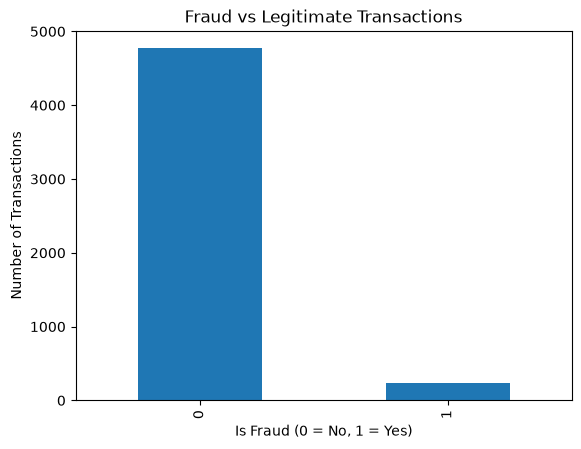

In [173]:
df['is_fraud'].value_counts().plot(kind='bar')
plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('Is Fraud (0 = No, 1 = Yes)')
plt.ylabel('Number of Transactions')
plt.show()

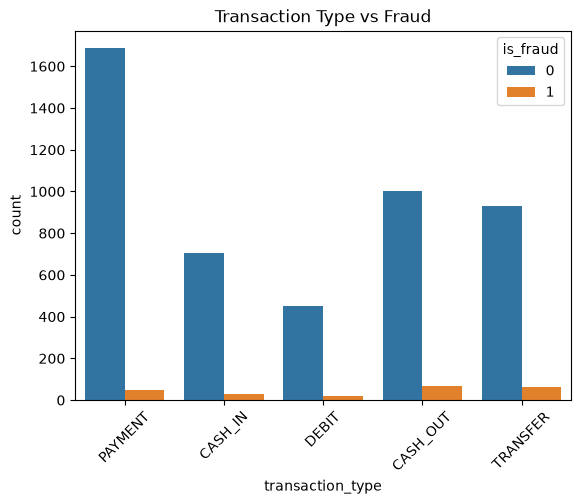

In [174]:
sns.countplot(data=df, x='transaction_type', hue='is_fraud')
plt.title('Transaction Type vs Fraud')
plt.xticks(rotation=45)
plt.show()

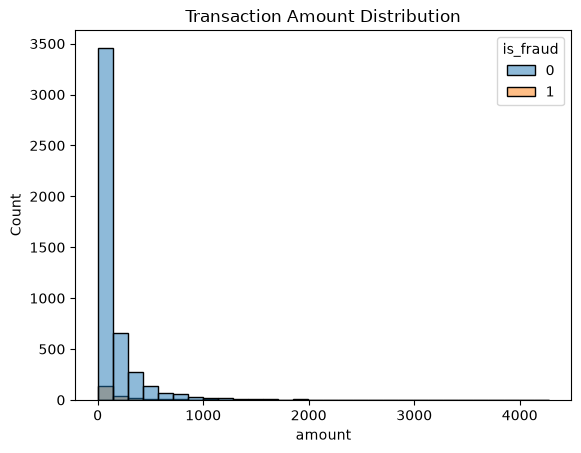

In [175]:
sns.histplot(data=df, x='amount', hue='is_fraud', bins=30)
plt.title('Transaction Amount Distribution')
plt.show()

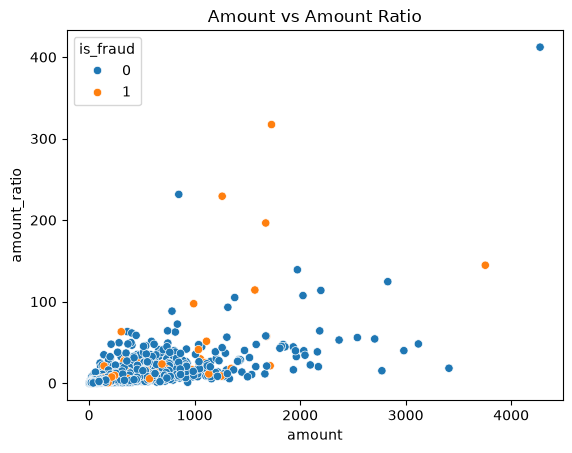

In [176]:
sns.scatterplot(
    data=df,
    x='amount',
    y='amount_ratio',
    hue='is_fraud'
)
plt.title('Amount vs Amount Ratio')
plt.show()

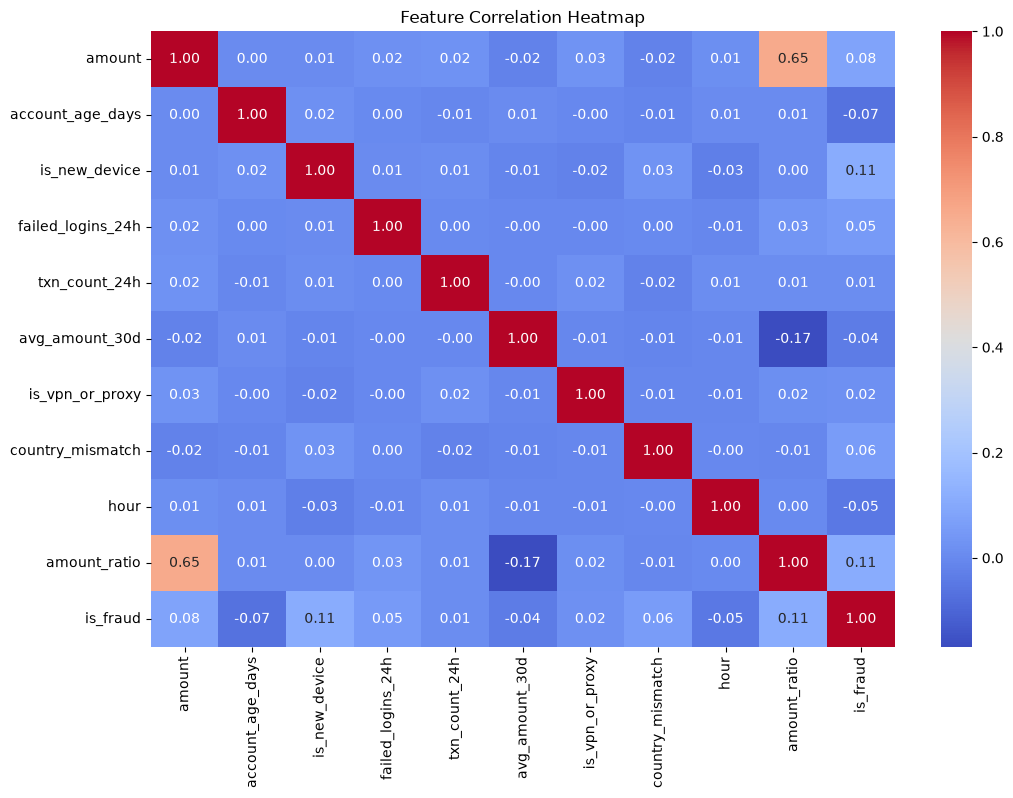

In [177]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

In [178]:

X = df.drop(columns=[
    'is_fraud',
    'transaction_id',
    'timestamp',
    'user_id'
])

y = df['is_fraud']


In [179]:
print(X.columns)
print(X.dtypes)

Index(['transaction_type', 'merchant_category', 'amount', 'account_age_days',
       'device_type', 'ip_country', 'billing_country', 'is_new_device',
       'failed_logins_24h', 'txn_count_24h', 'avg_amount_30d',
       'is_vpn_or_proxy', 'country_mismatch', 'hour', 'amount_ratio'],
      dtype='str')
transaction_type         str
merchant_category        str
amount               float64
account_age_days       int64
device_type              str
ip_country               str
billing_country          str
is_new_device          int64
failed_logins_24h      int64
txn_count_24h          int64
avg_amount_30d       float64
is_vpn_or_proxy        int64
country_mismatch       int64
hour                   int64
amount_ratio         float64
dtype: object


In [180]:
categorical_cols = [
    'transaction_type',
    'merchant_category',
    'device_type',
    'ip_country',
    'billing_country'
]

In [181]:

X = pd.get_dummies(X, columns=categorical_cols, dtype=int)


In [182]:
print(X.head())
print(X.shape)
print(X.dtypes)

   amount  account_age_days  is_new_device  failed_logins_24h  txn_count_24h  \
0   36.76               766              0                  1              3   
1  141.78              2920              1                  0              2   
2   23.09              3122              0                  1              4   
3   19.08              1122              0                  0              5   
4   83.34               862              0                  0              4   

   avg_amount_30d  is_vpn_or_proxy  country_mismatch  hour  amount_ratio  ...  \
0           10.47                0                 1     2          3.51  ...   
1           41.16                1                 1     2          3.44  ...   
2          181.37                0                 1     4          0.13  ...   
3           12.08                0                 0     5          1.58  ...   
4           22.12                0                 1     5          3.77  ...   

   billing_country_AU  billing_c

In [183]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [184]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4000, 46)
X_test: (1000, 46)
y_train: (4000,)
y_test: (1000,)


In [185]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [186]:
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [187]:
y_pred = model.predict(X_test_scaled)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.iloc[:10].values)


First 10 predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 actual values: [0 0 0 0 0 0 0 0 0 0]


In [188]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(classification_report(
    y_test, y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 95.50%
Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       954
           1       1.00      0.02      0.04        46

    accuracy                           0.95      1000
   macro avg       0.98      0.51      0.51      1000
weighted avg       0.96      0.95      0.93      1000

Confusion Matrix:
[[954   0]
 [ 45   1]]
              precision    recall  f1-score   support

  Legitimate       0.95      1.00      0.98       954
       Fraud       1.00      0.02      0.04        46

    accuracy                           0.95      1000
   macro avg       0.98      0.51      0.51      1000
weighted avg       0.96      0.95      0.93      1000

Confusion matrix:
[[954   0]
 [ 45   1]]


In [189]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


R2 Score: -0.025430680885972112
MAE: 0.045
RMSE: 0.21213203435596426


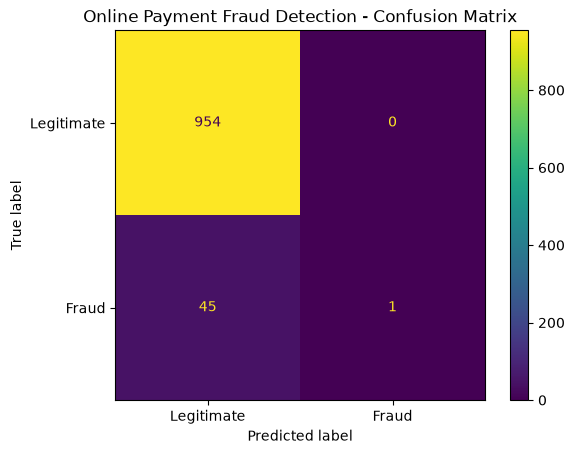

In [190]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Fraud"]
)
plt.title("Online Payment Fraud Detection - Confusion Matrix")
plt.show()


In [191]:
compare_df = pd.DataFrame({
    "Actual Y": y_test.reset_index(drop=True),
    "Model Predicted Value": pd.Series(y_pred)
})

compare_df["Result"] = np.where(
    compare_df["Actual Y"] == compare_df["Model Predicted Value"],
    "Correct",
    "Incorrect"
)

compare_df.head(20)


,Actual Y,Model Predicted Value,Result
0,0,0,Correct
1,0,0,Correct
2,0,0,Correct
3,0,0,Correct
4,0,0,Correct
5,0,0,Correct
6,0,0,Correct
7,0,0,Correct
8,0,0,Correct
9,0,0,Correct


In [192]:

amount = float(input("Amount: "))
age = int(input("Account age (days): "))
device = input("Device (mobile/desktop/tablet): ").strip().lower()
txn = input("Transaction type: ").strip().lower()
merchant = input("Merchant category: ").strip().lower()
ip = input("IP country: ").strip()
billing = input("Billing country: ").strip()
new = int(input("New device (1/0): "))
failed = int(input("Failed logins in 24 hours: "))
count = int(input("Transactions in 24 hours: "))
avg = float(input("Average amount (30 days): "))
vpn = int(input("VPN/Proxy (1/0): "))
hour = int(input("Transaction hour (0-23): "))

data = pd.DataFrame([{
    "amount": amount,
    "account_age_days": age,
    "device_type": device,
    "transaction_type": txn,
    "merchant_category": merchant,
    "ip_country": ip,
    "billing_country": billing,
    "is_new_device": new,
    "failed_logins_24h": failed,
    "txn_count_24h": count,
    "avg_amount_30d": avg,
    "is_vpn_or_proxy": vpn,
    "country_mismatch": int(ip != billing),
    "hour": hour,
    "amount_ratio": amount / (avg + 1)
}])


data = pd.get_dummies(
    data,
    columns=categorical_cols,
    dtype=int
).reindex(columns=X.columns, fill_value=0)

data_scaled = scaler.transform(data)
prediction = model.predict(data_scaled)[0]
fraud_probability = model.predict_proba(data_scaled)[0][1]

print("Prediction:", "Fraud" if prediction == 1 else "Legitimate")
print(f"Estimated fraud probability: {fraud_probability:.2%}")


Prediction: Fraud
Estimated fraud probability: 99.91%
